# Course 10: Deep Learning on Curved Spaces
## Session 11: Generative models on manifolds

**Goal:** sample from von Mises–Fisher and wrapped distributions on the sphere with the right volume measure, train a Riemannian flow matching model whose samples stay on the sphere, and compare it with Euclidean flow matching followed by normalization.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Distributions on the sphere, and the right volume measure
The **von Mises–Fisher (vMF)** distribution on the unit sphere $S^2$ (Fisher 1953) has density $f(x) = C(\kappa)\,e^{\kappa\,\mu^\top x}$ with respect to surface area, with mean direction $\mu$ and concentration $\kappa$; on $S^2$, $C(\kappa) = \dfrac{\kappa}{4\pi\sinh\kappa}$. We evaluate it as $\dfrac{\kappa}{2\pi(1 - e^{-2\kappa})}e^{\kappa(\mu^\top x - 1)}$, which does not overflow for large $\kappa$.

**Sampling on $S^2$.** Area on the sphere is uniform in $w = \mu^\top x$ (Archimedes), so $w$ has density proportional to $e^{\kappa w}$ on $[-1, 1]$ and inverting its CDF gives $w = 1 + \frac{1}{\kappa}\log\big(u + (1 - u)e^{-2\kappa}\big)$ for $u$ uniform on $(0, 1)$. Then $x = w\mu + \sqrt{1 - w^2}\,v$ with $v$ a uniform unit vector orthogonal to $\mu$. The mean of $w$ should be $\coth\kappa - 1/\kappa$.

**Densities need the right volume measure.** In spherical coordinates around $\mu$ the area element is $\sin\theta\,d\theta\,d\varphi$, not $d\theta\,d\varphi$. A **wrapped normal** draws $v \sim N(0, \sigma^2 I)$ in the tangent plane at $\mu$ and maps it by $\exp_\mu$. Its density on the sphere is the tangent density times $r/\sin r$ with $r = \|v\|$ (for $r < \pi$), because $\exp_\mu$ shrinks a circle of radius $r$ in the plane, length $2\pi r$, to a circle of length $2\pi\sin r$. The cell checks these integrals with and without the right factors.

The data for the rest of the notebook: a **synthetic** mixture of four vMF distributions, standing in for event locations on Earth such as earthquakes, floods or storm formation sites; one cluster sits over the Bay of Bengal.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.integrate import quad

t_start = time.time()
torch.set_num_threads(1)
np.random.seed(0); torch.manual_seed(0)

def lonlat_to_xyz(lon, lat):
    lon, lat = np.deg2rad(lon), np.deg2rad(lat)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], -1)

def xyz_to_lonlat(x):
    return np.rad2deg(np.arctan2(x[:, 1], x[:, 0])), np.rad2deg(np.arcsin(np.clip(x[:, 2], -1, 1)))

def vmf_density(cos_angle, kappa):                           # density as a function of mu^T x
    return kappa / (2 * np.pi * (1 - np.exp(-2 * kappa))) * np.exp(kappa * (cos_angle - 1))

def sample_vmf(mu, kappa, n, rng):
    u = rng.uniform(size=n)
    w = 1 + np.log(u + (1 - u) * np.exp(-2 * kappa)) / kappa
    v = rng.normal(size=(n, 3)); v -= (v @ mu)[:, None] * mu; v /= np.linalg.norm(v, axis=1, keepdims=True)
    return w[:, None] * mu + np.sqrt(np.clip(1 - w**2, 0, None))[:, None] * v

rng = np.random.default_rng(0)
mu = np.array([0.0, 0.0, 1.0])
print("kappa   integral with sin(theta)   without   mean of mu.x: samples   coth(k) - 1/k")
for kappa in [1, 10, 100]:
    with_sin = 2 * np.pi * quad(lambda th: vmf_density(np.cos(th), kappa) * np.sin(th), 0, np.pi, points=[0.1, 0.5])[0]
    without = 2 * np.pi * quad(lambda th: vmf_density(np.cos(th), kappa), 0, np.pi, points=[0.1, 0.5])[0]
    xs = sample_vmf(mu, kappa, 200_000, rng)
    print(f"{kappa:5d}   {with_sin:24.10f}   {without:7.3f}   {(xs @ mu).mean():21.5f}   {1 / np.tanh(kappa) - 1 / kappa:13.5f}")
print(f"samples lie on the sphere: largest | |x| - 1 | = {np.abs(np.linalg.norm(xs, axis=1) - 1).max():.1e}")

sigma = 0.5                                                   # wrapped normal: tangent Gaussian density times r / sin r
gauss = lambda r: np.exp(-r**2 / (2 * sigma**2)) / (2 * np.pi * sigma**2)
print(f"wrapped normal, sigma = {sigma}: integral over the sphere with the factor r/sin r "
      f"{2 * np.pi * quad(lambda r: gauss(r) * r / np.sin(r) * np.sin(r), 0, np.pi)[0]:.6f}; "
      f"without it {2 * np.pi * quad(lambda r: gauss(r) * np.sin(r), 0, np.pi)[0]:.6f}")

centres = lonlat_to_xyz(np.array([89, -60, 140, 20]), np.array([18, -10, 35, 50]))
kappas, weights = np.array([30, 20, 60, 15]), np.array([0.4, 0.3, 0.2, 0.1])
def sample_data(n, rng):
    comp = rng.choice(4, n, p=weights)
    out = np.zeros((n, 3))
    for k in range(4):
        out[comp == k] = sample_vmf(centres[k], kappas[k], (comp == k).sum(), rng)
    return out
train_np = sample_data(20_000, np.random.default_rng(1))
test, test2 = sample_data(3000, np.random.default_rng(2)), sample_data(3000, np.random.default_rng(3))
data = torch.tensor(train_np, dtype=torch.float32)
print(f"training set {len(train_np)} points; two independent test sets of {len(test)}")

kappa   integral with sin(theta)   without   mean of mu.x: samples   coth(k) - 1/k
    1               1.0000000000     1.692                 0.31206         0.31304
   10               1.0000000000     4.016                 0.89996         0.90000
  100               1.0000000000    12.549                 0.99001         0.99000
samples lie on the sphere: largest | |x| - 1 | = 1.1e-16
wrapped normal, sigma = 0.5: integral over the sphere with the factor r/sin r 1.000000; without it 0.920689
training set 20000 points; two independent test sets of 3000


### 2. Riemannian flow matching on the sphere
Flow matching (Course 3 session 9) trains a velocity field $v_\theta(x, t)$ that carries a simple distribution at $t = 0$ to the data at $t = 1$, by regression on per-pair targets. Riemannian flow matching (Chen & Lipman 2024) does this on a manifold:

* draw $x_0$ uniform on the sphere and $x_1$ from the data;
* follow the geodesic $x_t = \exp_{x_0}\big(t\log_{x_0}(x_1)\big)$;
* the target velocity is $u_t = \log_{x_t}(x_1)/(1 - t)$: the tangent vector at $x_t$ that points to $x_1$, with length equal to the whole geodesic's length, so the remaining distance is covered at constant speed;
* the network's output is projected onto the tangent plane, $P_x v = v - (x^\top v)x$, and the loss is $\|P_{x_t}v_\theta(x_t, t) - u_t\|^2$;
* to sample, take Euler steps along the sphere: $x \leftarrow \exp_x\big(h\,P_x v_\theta(x, t)\big)$.

The exp and log maps are session 3's, with $\log_x(y) = d(x, y)\,\dfrac{y - (x^\top y)x}{\|y - (x^\top y)x\|}$ and $d$ computed with atan2. The cell checks that $u_t$ really is the velocity of $x_t$ (by a finite difference), that it is tangent, and that its length is $d(x_0, x_1)$, then trains the model: a 3-layer MLP of width 128 on $(x, t, \sin 2\pi t, \cos 2\pi t)$, 3,000 Adam steps with batches of 512.

In [2]:
def proj(x, v):
    return v - (x * v).sum(-1, keepdim=True) * x

def expmap(x, v):
    n = v.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return torch.cos(n) * x + torch.sin(n) * v / n

def logmap(x, y):
    u = proj(x, y); nu = u.norm(dim=-1, keepdim=True).clamp_min(1e-12)
    return torch.atan2(nu, (x * y).sum(-1, keepdim=True)) * u / nu

def uniform_sphere(n, g, dtype=torch.float32):
    x = torch.randn(n, 3, generator=g, dtype=dtype)
    return x / x.norm(dim=-1, keepdim=True)

g = torch.Generator().manual_seed(0)
x0, x1 = uniform_sphere(1000, g, torch.float64), uniform_sphere(1000, g, torch.float64)
t, h = torch.rand(1000, 1, generator=g, dtype=torch.float64) * 0.9, 1e-6
path = lambda s: expmap(x0, s * logmap(x0, x1))
ut = logmap(path(t), x1) / (1 - t)
fd = (path(t + h) - path(t - h)) / (2 * h)
print(f"target vs finite-difference velocity: {(ut - fd).abs().max():.1e}; tangent: {(ut * path(t)).sum(-1).abs().max():.1e}; "
      f"|u_t| - d(x0, x1): {(ut.norm(dim=-1) - torch.atan2(torch.linalg.cross(x0, x1).norm(dim=-1), (x0 * x1).sum(-1))).abs().max():.1e}")
print(f"exp/log round trip: {(expmap(x0, logmap(x0, x1)) - x1).abs().max():.1e}")

class VelocityField(torch.nn.Module):
    def __init__(self, width=128):
        super().__init__()
        self.net = torch.nn.Sequential(torch.nn.Linear(6, width), torch.nn.SiLU(), torch.nn.Linear(width, width), torch.nn.SiLU(),
                                       torch.nn.Linear(width, width), torch.nn.SiLU(), torch.nn.Linear(width, 3))
    def forward(self, x, t):
        t = t.expand(x.shape[0], 1)
        return self.net(torch.cat([x, t, torch.sin(2 * np.pi * t), torch.cos(2 * np.pi * t)], -1))

def train(kind, steps=3000, bs=512):
    torch.manual_seed(0); g = torch.Generator().manual_seed(0)
    model = VelocityField()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses, t0 = [], time.time()
    for it in range(steps):
        x1 = data[torch.randint(0, len(data), (bs,), generator=g)]
        t = torch.rand(bs, 1, generator=g) * 0.999                    # avoid t = 1, where log/(1 - t) is 0/0
        if kind == "Riemannian":
            x0 = uniform_sphere(bs, g)
            xt = expmap(x0, t * logmap(x0, x1)); target = logmap(xt, x1) / (1 - t)
            pred = proj(xt, model(xt, t))
        else:                                                         # Euclidean flow matching in R^3
            x0 = torch.randn(bs, 3, generator=g)
            xt = (1 - t) * x0 + t * x1; target = x1 - x0
            pred = model(xt, t)
        loss = ((pred - target) ** 2).sum(-1).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
    print(f"{kind} flow matching: trained in {time.time() - t0:.1f} s, final loss (mean of last 100 steps) {np.mean(losses[-100:]):.3f}")
    return model

model_r = train("Riemannian")

target vs finite-difference velocity: 3.5e-10; tangent: 4.2e-15; |u_t| - d(x0, x1): 4.4e-15
exp/log round trip: 7.8e-16


Riemannian flow matching: trained in 7.5 s, final loss (mean of last 100 steps) 2.069


### 3. The Euclidean alternative: flow matching in $\mathbb{R}^3$, then normalize
The tempting shortcut: treat the data as points in $\mathbb{R}^3$, train ordinary flow matching from a standard Gaussian with straight paths $x_t = (1 - t)x_0 + tx_1$ and target $x_1 - x_0$, sample, and divide each sample by its length at the end. Same network, same number of steps and batch size.

In [3]:
model_e = train("Euclidean")

Euclidean flow matching: trained in 6.4 s, final loss (mean of last 100 steps) 1.822


### 4. Sampling and evaluation
We sample 3,000 points from each model with $N$ Euler steps (in float64), and compare them with held-out data using the **maximum mean discrepancy** (MMD; Gretton et al. 2012): $\text{MMD}^2 = E\,k(x, x') + E\,k(y, y') - 2E\,k(x, y)$, estimated without bias. The kernel $k(x, y) = e^{\kappa(x^\top y - 1)} = e^{-\kappa(1 - \cos d(x, y))}$ with $\kappa = 10$ depends only on the geodesic distance $d$ and is positive definite on the sphere (it is the exponential of the positive definite kernel $\kappa\,x^\top y$, times a constant). For reference we also compute MMD$^2$ between two independent data sets (the noise floor) and for uniform points.

Other checks: how far the Euclidean samples are from the sphere before normalization, the mass of each cluster (nearest centre), and the fraction of samples more than 45° from every centre (mass leaking between clusters).

In [4]:
@torch.no_grad()
def sample(model, kind, n=3000, steps=100, seed=5):
    m = model.double(); g = torch.Generator().manual_seed(seed)
    x = uniform_sphere(n, g, torch.float64) if kind == "Riemannian" else torch.randn(n, 3, generator=g, dtype=torch.float64)
    h = 1.0 / steps
    for k in range(steps):
        v = m(x, torch.full((1, 1), k * h, dtype=torch.float64))
        x = expmap(x, h * proj(x, v)) if kind == "Riemannian" else x + h * v
    model.float()
    return x.numpy()

def mmd2(X, Y, kappa=10.0):
    Kxx, Kyy, Kxy = np.exp(kappa * (X @ X.T - 1)), np.exp(kappa * (Y @ Y.T - 1)), np.exp(kappa * (X @ Y.T - 1))
    n, m = len(X), len(Y)
    return (Kxx.sum() - np.trace(Kxx)) / (n * (n - 1)) + (Kyy.sum() - np.trace(Kyy)) / (m * (m - 1)) - 2 * Kxy.mean()

masses = lambda X: np.bincount(np.argmax(X @ centres.T, 1), minlength=4) / len(X)
far = lambda X: np.mean(np.max(X @ centres.T, 1) < np.cos(np.pi / 4))
unif = np.random.default_rng(4).normal(size=(3000, 3)); unif /= np.linalg.norm(unif, axis=1, keepdims=True)
print(f"noise floor, data vs data: MMD^2 = {mmd2(test2, test):.5f}; uniform vs data: {mmd2(unif, test):.5f}")
print(f"data: cluster masses {np.round(masses(test2), 3)} (true {weights}), beyond 45 degrees {far(test2):.4f}")

step_list, curves, out = [5, 10, 25, 100], {"Riemannian": [], "Euclidean": []}, {}
for steps in step_list:
    xr = sample(model_r, "Riemannian", steps=steps)
    xe = sample(model_e, "Euclidean", steps=steps)
    radius = np.linalg.norm(xe, axis=1); xe_n = xe / radius[:, None]
    curves["Riemannian"].append(mmd2(xr, test)); curves["Euclidean"].append(mmd2(xe_n, test))
    out[steps] = (xr, xe, radius, xe_n)
    print(f"{steps:3d} Euler steps: MMD^2 Riemannian {curves['Riemannian'][-1]:.5f}, Euclidean + normalize {curves['Euclidean'][-1]:.5f}; "
          f"Riemannian samples off the sphere by at most {np.abs(np.linalg.norm(xr, axis=1) - 1).max():.1e}; "
          f"Euclidean samples: mean | |x| - 1 | = {np.abs(radius - 1).mean():.3f}, {np.mean(np.abs(radius - 1) > 0.1):.1%} off by more than 0.1")
xr, xe, radius, xe_n = out[100]
print(f"100 steps, cluster masses: Riemannian {np.round(masses(xr), 3)}, Euclidean {np.round(masses(xe_n), 3)}; "
      f"beyond 45 degrees: {far(xr):.4f} and {far(xe_n):.4f}")

noise floor, data vs data: MMD^2 = -0.00004; uniform vs data: 0.13770
data: cluster masses [0.41  0.286 0.207 0.096] (true [0.4 0.3 0.2 0.1]), beyond 45 degrees 0.0013


  5 Euler steps: MMD^2 Riemannian 0.00639, Euclidean + normalize 0.02151; Riemannian samples off the sphere by at most 6.7e-16; Euclidean samples: mean | |x| - 1 | = 0.097, 23.7% off by more than 0.1


 10 Euler steps: MMD^2 Riemannian 0.00226, Euclidean + normalize 0.00975; Riemannian samples off the sphere by at most 1.1e-15; Euclidean samples: mean | |x| - 1 | = 0.049, 9.9% off by more than 0.1


 25 Euler steps: MMD^2 Riemannian 0.00122, Euclidean + normalize 0.00558; Riemannian samples off the sphere by at most 2.1e-15; Euclidean samples: mean | |x| - 1 | = 0.044, 9.5% off by more than 0.1


100 Euler steps: MMD^2 Riemannian 0.00093, Euclidean + normalize 0.00419; Riemannian samples off the sphere by at most 5.6e-15; Euclidean samples: mean | |x| - 1 | = 0.043, 9.3% off by more than 0.1
100 steps, cluster masses: Riemannian [0.384 0.294 0.21  0.112], Euclidean [0.393 0.289 0.218 0.1  ]; beyond 45 degrees: 0.0147 and 0.0103


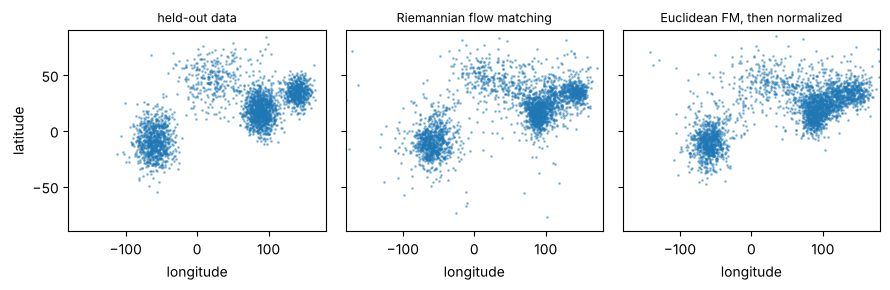

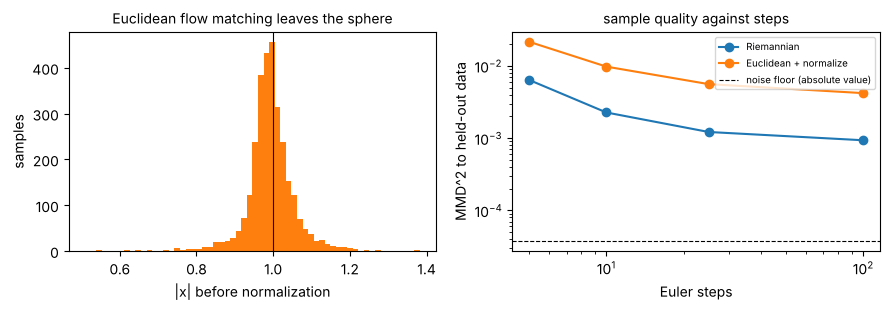

runtime so far 22 s


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3.0), sharey=True)
for a, (X, title) in zip(ax, [(test, "held-out data"), (xr, "Riemannian flow matching"), (xe_n, "Euclidean FM, then normalized")]):
    lon, lat = xyz_to_lonlat(X)
    a.scatter(lon, lat, s=1, alpha=0.4)
    a.set_xlim(-180, 180); a.set_ylim(-90, 90); a.set_title(title, fontsize=9); a.set_xlabel("longitude")
ax[0].set_ylabel("latitude")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(radius, bins=60, color="C1")
ax[0].axvline(1, color="k", lw=0.8); ax[0].set_xlabel("|x| before normalization"); ax[0].set_ylabel("samples")
ax[0].set_title("Euclidean flow matching leaves the sphere", fontsize=10)
for kind, col in [("Riemannian", "C0"), ("Euclidean", "C1")]:
    ax[1].plot(step_list, curves[kind], "o-", color=col, label=kind if kind == "Riemannian" else "Euclidean + normalize")
ax[1].axhline(abs(mmd2(test2, test)), color="k", ls="--", lw=0.8, label="noise floor (absolute value)")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("Euler steps"); ax[1].set_ylabel("MMD^2 to held-out data")
ax[1].set_title("sample quality against steps", fontsize=10); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.0f} s")

### 5. Exercises

In [6]:
# TODO: Euclidean flow matching from the uniform distribution on the sphere instead of a Gaussian. The straight
# paths are now chords through the inside of the ball. Train it with train()'s Euclidean branch (change the base),
# sample with 100 steps, and return (mean | |x| - 1 | before normalization, MMD^2 after). Where do the chords
# between nearly opposite points pass, and what does the network have to learn there?
def chord_flow_matching():
    return None          # replace with your code

r = chord_flow_matching()
print("not done yet" if r is None else r)

not done yet


In [7]:
# TODO: flow matching on the torus. Protein backbone angles (phi, psi) live on the torus S^1 x S^1 (Course 7
# session 9). There the geodesic from a to b moves each angle along the shorter way round: log_a(b) =
# wrap(b - a) with wrap(d) = (d + pi) mod 2 pi - pi, and exp_a(v) = wrap(a + v). Build a synthetic data set of
# three clusters of angle pairs, train Riemannian flow matching from the uniform distribution on the torus, and
# return the MMD^2 of 2,000 samples against held-out data (use the kernel prod_j exp(k (cos(x_j - y_j) - 1))).
def torus_flow_matching():
    return None          # replace with your code

r = torus_flow_matching()
print("not done yet" if r is None else r)

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds, except the timings.)

1. **The volume measure matters.** With the area element $\sin\theta\,d\theta\,d\varphi$ the vMF density integrated to 1.0000000000 for $\kappa$ = 1, 10 and 100; treating $(\theta, \varphi)$ as flat gave 1.692, 4.016 and 12.549. The wrapped normal integrated to 1.000000 with the factor $r/\sin r$ and to 0.920689 without it. The sampler's mean of $\mu^\top x$ matched $\coth\kappa - 1/\kappa$ (for example 0.89996 against 0.90000 at $\kappa = 10$).
2. **The flow-matching target is right.** $u_t = \log_{x_t}(x_1)/(1 - t)$ matched a finite-difference velocity of the geodesic to 3.5e-10, was tangent to 4.2e-15, and had length $d(x_0, x_1)$ to 4.4e-15.
3. **Riemannian samples never leave the sphere.** After 100 exp-map steps they were within 5.6e-15 of it. The Euclidean samples were off by 0.043 on average at 100 steps, with 9.3% off by more than 0.1, and by 0.097 at 5 steps (23.7% off by more than 0.1).
4. **Riemannian flow matching matched the data better at every number of steps.** MMD$^2$ was 0.00093 against 0.00419 at 100 steps, and between 3.4 and 4.6 times lower at 5, 10 and 25 steps. Both cluster masses were close to the true weights.
5. **Neither model is finished, and not every measure favours the Riemannian one.** Both MMD$^2$ values stayed far above the noise floor (0.00004 in absolute value; uniform points give 0.13770), and the maps show smearing between clusters after only 3,000 training steps. Against expectation, the Euclidean model leaked less mass between clusters: 1.03% of its samples were more than 45° from every centre, against 1.47% for the Riemannian model and 0.13% for the data.